In [1]:
# Importing Libraries
import pandas as pd
from datasets import load_dataset

import matplotlib.pyplot as plt

# Loading the dataset
dataset = load_dataset("lukebarousse/data_jobs")
df = dataset['train'].to_pandas()

#data cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
import ast
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\Dell\anaconda3\envs\Best_Room\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Axes: xlabel='job_title_short'>

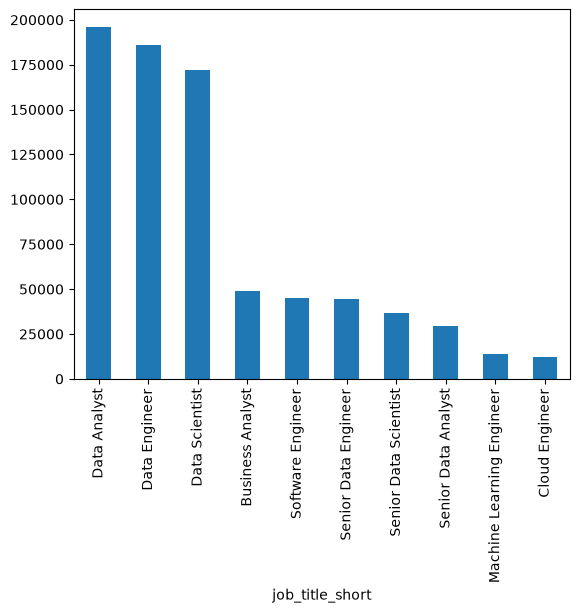

In [2]:
fig,ax = plt.subplots()

df['job_title_short'].value_counts().plot(kind='bar', ax=ax) 

In [3]:
df['job_schedule_type'].value_counts().head(3)

job_schedule_type
Full-time     701727
Contractor     34793
Internship      8742
Name: count, dtype: int64

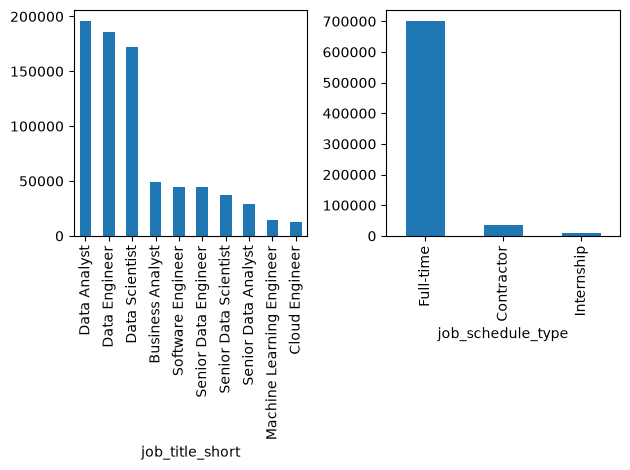

In [4]:
fig,ax = plt.subplots(1, 2)

df['job_title_short'].value_counts().plot(kind='bar', ax=ax[0])
df['job_schedule_type'].value_counts().head(3).plot(kind='bar', ax=ax[1])

fig.tight_layout()

In [22]:
# Select only the required columns
df_skills = df[['job_skills', 'job_title_short']].copy()

# Convert job_title_short to category to save memory
df_skills['job_title_short'] = df_skills['job_title_short'].astype('category')

# Remove missing skills
df_skills = df_skills.dropna(subset=['job_skills'])

# Expand job_skills
df_skills = df_skills.explode('job_skills')

# Group and count skills
skills_count = df_skills.groupby(
    ['job_skills', 'job_title_short'],
    observed=True
).size()

# Convert to DataFrame
df_skills_count = skills_count.reset_index(name='skill_count')

# Sort in descending order
df_skills_count = df_skills_count.sort_values(
    by='skill_count',
    ascending=False
)

df_skills_count

,job_skills,job_title_short,skill_count
1480,python,Data Scientist,113711
1822,sql,Data Engineer,113130
1479,python,Data Engineer,108022
1821,sql,Data Analyst,92428
1823,sql,Data Scientist,78982
...,...,...,...
2173,webex,Senior Data Scientist,1
293,codecommit,Business Analyst,1
2233,xamarin,Machine Learning Engineer,1
1087,mlr,Machine Learning Engineer,1


In [23]:
job_titles = ['Data Scientist', 'Data Analyst', 'Data Engineer']

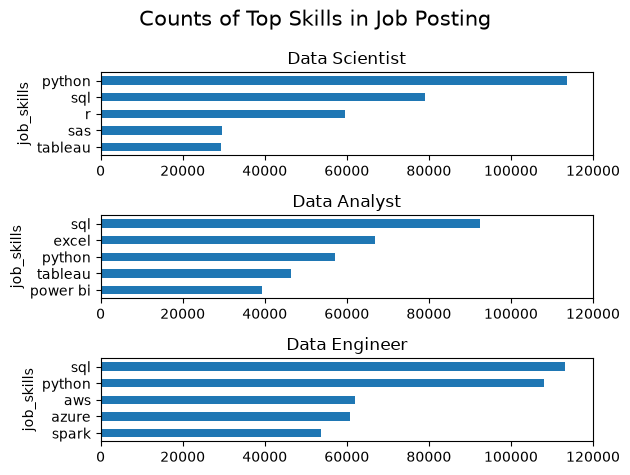

In [31]:
fig, ax = plt.subplots(3, 1)

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count['job_title_short'] == job_title].head(5)
    df_plot.plot( kind='barh', x='job_skills',  y='skill_count', ax=ax[i], title=job_title)
    ax[i].invert_yaxis()  # Invert y-axis for better readability
    ax[i].legend().set_visible(False)  # Hide legend for each subplot 
    ax[i].set_xlim(0, 120000)  

fig.suptitle('Counts of Top Skills in Job Posting', fontsize=15)
fig.tight_layout()
